# 4. Диагностика: классы спроса и метрики

**Сквозной вопрос блока:** почему на нулях ломаются и модели, и метрики — и что с этим делать.

В этом ноутбуке:
- Что такое прерывистый спрос, примеры из M5;
- Классификация ADI / CV² (Syntetos–Boylan–Croston);
- Почему MAE «любит» нулевой прогноз;
- Метрики для прерывистого спроса (RMSSE, bias);
- Бейзлайны: ноль, Naive, SeasonalNaive, SES.

Загрузка данных, разбиение, классификация и расчёт метрик вынесены в `utils.py` рядом с ноутбуками:
этот код одинаков во всех трёх ноутбуках про прерывистый спрос (4, 5, 6). Здесь мы один раз разберём,
как устроены классификация и метрики, а дальше будем пользоваться функциями модуля.

In [1]:
import warnings

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsforecast import StatsForecast
from statsforecast.models import (
    Naive,
    SeasonalNaive,
    HistoricAverage,
    SimpleExponentialSmoothing,
)

from utils import (
    demand_classes,
    evaluate_by_class,
    highlight_best,
    load_m5_ca1,
    metric_table,
    to_sf_format,
    train_test_split,
)

sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 4)

## 0. Данные: M5 CA_1

M5 Competition: Walmart, дневные продажи товаров. Подвыборка — магазин CA_1 (Калифорния), все 3049 товаров.
Формат: wide (d_1, d_2, ..., d_1913) → преобразуем в long.

`load_m5_ca1()` читает `sales_train_validation.csv.gz`, фильтрует CA_1, плавит wide → long и подтягивает
даты из `calendar.csv`. Дальше работаем в формате Nixtla — `unique_id`, `ds`, `y`: его ждут и
`statsforecast`, и `utilsforecast`.

In [2]:
df_long = load_m5_ca1()

print(f"Товаров в CA_1: {df_long['id'].nunique()}")
print(f"Дней: {df_long['d'].nunique()}")
print(f"Long-формат: {len(df_long)} строк")
print(f"Период: {df_long['date'].min().date()} — {df_long['date'].max().date()}")

df_long.head(3)

Товаров в CA_1: 3049
Дней: 1913
Long-формат: 5832737 строк
Период: 2011-01-29 — 2016-04-24


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date
0,FOODS_1_001_CA_1_validation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_1,3,2011-01-29
1,FOODS_1_001_CA_1_validation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_2,0,2011-01-30
2,FOODS_1_001_CA_1_validation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA,d_3,0,2011-01-31


## 1. Что такое прерывистый спрос

Прерывистый (intermittent) спрос: много нулей между ненулевыми значениями. Типично для:
- редких товаров (запчасти, специализированная продукция);
- новых товаров;
- товаров с высокой ценой или длинным циклом покупки.

**Проблема:** классические модели (ETS, ARIMA) предполагают непрерывный ряд, на нулях дают плохие результаты.

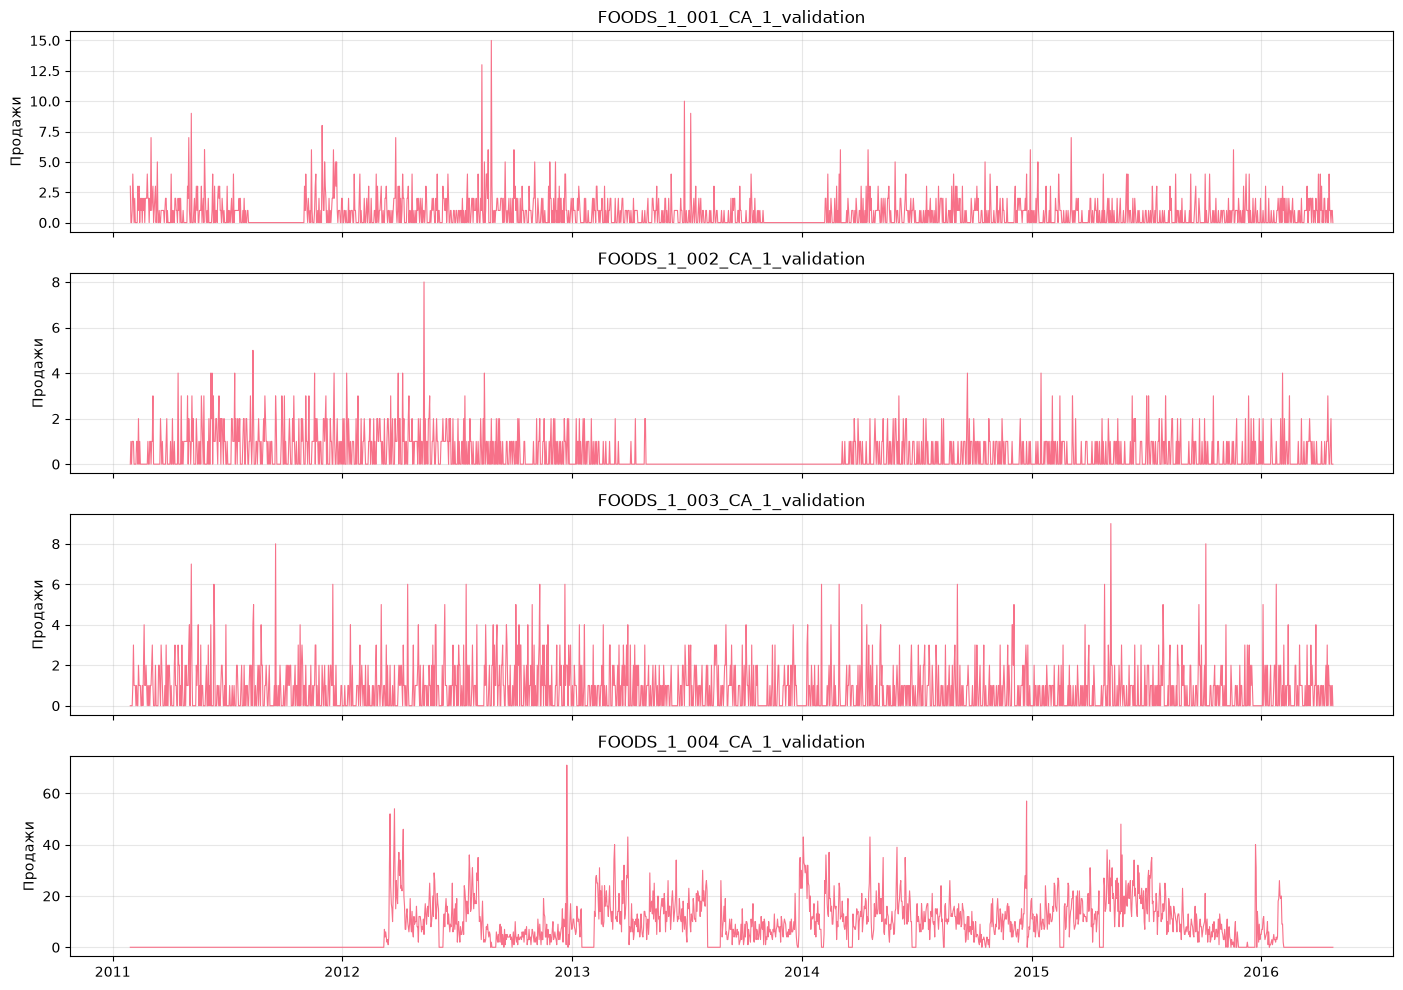

In [3]:
# Примеры рядов по одному из каждого класса (выберем позже)
# Пока визуализируем первые 4 товара
sample_ids = df_long['id'].unique()[:4]

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

for ax, item_id in zip(axes, sample_ids):
    item_data = df_long[df_long['id'] == item_id]
    ax.plot(item_data['date'], item_data['sales'], linewidth=0.8)
    ax.set_ylabel('Продажи')
    ax.set_title(f'{item_id}')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

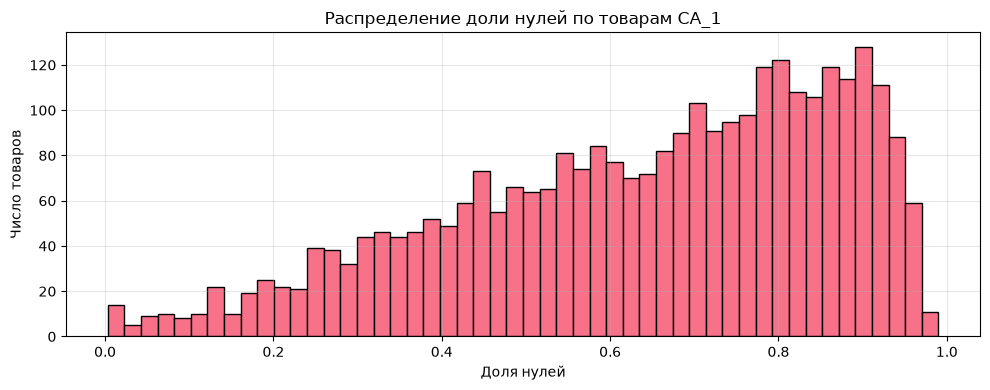

Медианная доля нулей: 0.69
Товаров с >50% нулей: 2218 из 3049


In [4]:
# Доля нулей по товарам
zero_fraction = df_long.groupby('id')['sales'].apply(lambda x: (x == 0).mean())

plt.figure(figsize=(10, 4))
plt.hist(zero_fraction, bins=50, edgecolor='black')
plt.xlabel('Доля нулей')
plt.ylabel('Число товаров')
plt.title('Распределение доли нулей по товарам CA_1')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Медианная доля нулей: {zero_fraction.median():.2f}")
print(f"Товаров с >50% нулей: {(zero_fraction > 0.5).sum()} из {len(zero_fraction)}")

## 2. Классификация ADI / CV²

Syntetos, Boylan, Croston (2005): два параметра характеризуют спрос:
- **ADI** (Average Demand Interval) = средний интервал между ненулевыми продажами;
- **CV²** = (σ / μ)² = квадрат коэффициента вариации ненулевых продаж.

Пороги (Syntetos & Boylan):
- ADI < 1.32 и CV² < 0.49 → **smooth** (гладкий);
- ADI ≥ 1.32 и CV² < 0.49 → **intermittent** (прерывистый);
- ADI < 1.32 и CV² ≥ 0.49 → **erratic** (неустойчивый);
- ADI ≥ 1.32 и CV² ≥ 0.49 → **lumpy** (комковатый).

Ниже — эталонная реализация в виде цикла: так классификация читается проще всего.
Рабочая версия — `demand_classes` в `utils.py`: то же самое, но векторизованно (без цикла по 3049 товарам).

In [5]:
def classify_demand(series):
    """
    Классификация временного ряда по ADI и CV².

    Возвращает: {'adi': float, 'cv2': float, 'class': str}
    """
    # Интервалы между ненулевыми значениями
    nonzero_idx = np.where(series > 0)[0]

    if len(nonzero_idx) == 0:
        return {'adi': np.inf, 'cv2': np.inf, 'class': 'lumpy', 'zero_count': len(series)}

    if len(nonzero_idx) == 1:
        adi = len(series)
        cv2 = 0
    else:
        intervals = np.diff(nonzero_idx)
        adi = intervals.mean() if len(intervals) > 0 else len(series)

        nonzero_vals = series[nonzero_idx]
        if nonzero_vals.mean() > 0:
            cv2 = (nonzero_vals.std() / nonzero_vals.mean()) ** 2
        else:
            cv2 = 0

    # Классификация
    if adi < 1.32 and cv2 < 0.49:
        demand_class = 'smooth'
    elif adi >= 1.32 and cv2 < 0.49:
        demand_class = 'intermittent'
    elif adi < 1.32 and cv2 >= 0.49:
        demand_class = 'erratic'
    else:
        demand_class = 'lumpy'

    return {
        'adi': adi,
        'cv2': cv2,
        'class': demand_class,
        'zero_count': (series == 0).sum()
    }

In [6]:
# Проверим, что эталон и модуль дают одно и то же на всех товарах
sample_check = df_long[df_long['id'] == sample_ids[0]]['sales'].values
print(classify_demand(sample_check))

sf_df = to_sf_format(df_long)
print(demand_classes(sf_df).head())

{'adi': 2.29136690647482, 'cv2': 0.5550380720041398, 'class': 'lumpy', 'zero_count': 1078}
                                  adi       cv2         class
unique_id                                                    
FOODS_1_001_CA_1_validation  2.291367  0.555038         lumpy
FOODS_1_002_CA_1_validation  3.009464  0.270918  intermittent
FOODS_1_003_CA_1_validation  2.116537  0.392257  intermittent
FOODS_1_004_CA_1_validation  1.102623  0.459180        smooth
FOODS_1_005_CA_1_validation  2.167800  0.848414         lumpy


                                  adi       cv2         class
unique_id                                                    
FOODS_1_001_CA_1_validation  2.291367  0.555038         lumpy
FOODS_1_002_CA_1_validation  3.009464  0.270918  intermittent
FOODS_1_003_CA_1_validation  2.116537  0.392257  intermittent
FOODS_1_004_CA_1_validation  1.102623  0.459180        smooth
FOODS_1_005_CA_1_validation  2.167800  0.848414         lumpy


In [7]:
class_df = demand_classes(sf_df)

In [8]:
# Распределение классов
class_counts = class_df['class'].value_counts()
print("Распределение классов спроса:\n")
print(class_counts)
print(f"\nДоли:\n{(class_counts / len(class_df) * 100).round(1)}")

Распределение классов спроса:

class
intermittent    2191
lumpy            541
smooth           237
erratic           80
Name: count, dtype: int64

Доли:
class
intermittent    71.9
lumpy           17.7
smooth           7.8
erratic          2.6
Name: count, dtype: float64


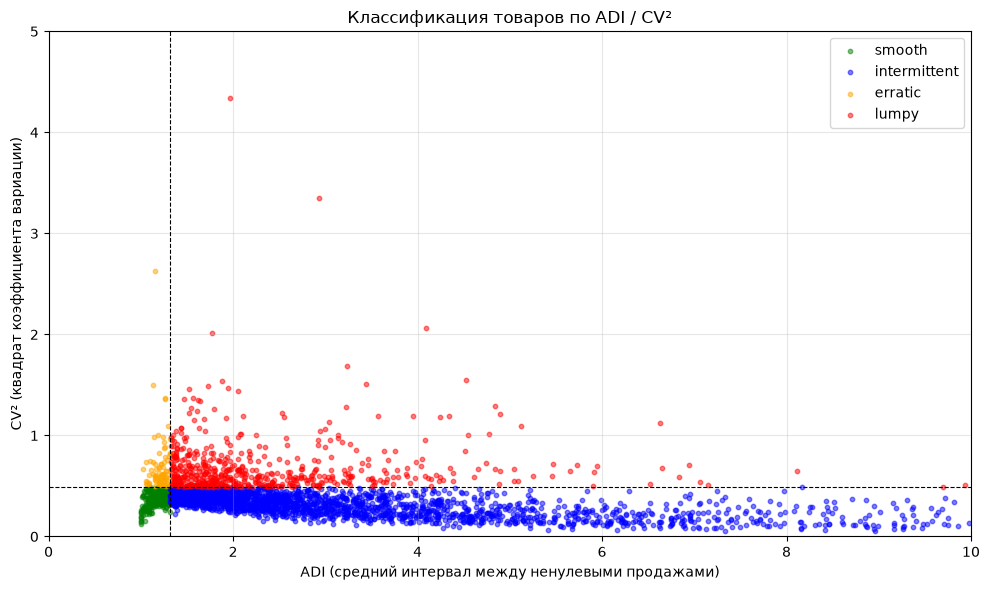

In [9]:
# Scatter ADI vs CV²
fig, ax = plt.subplots(figsize=(10, 6))

colors = {'smooth': 'green', 'intermittent': 'blue', 'erratic': 'orange', 'lumpy': 'red'}

for cls in ['smooth', 'intermittent', 'erratic', 'lumpy']:
    subset = class_df[class_df['class'] == cls]
    ax.scatter(subset['adi'], subset['cv2'], alpha=0.5, label=cls, s=10, color=colors[cls])

ax.axvline(1.32, color='black', linestyle='--', linewidth=0.8)
ax.axhline(0.49, color='black', linestyle='--', linewidth=0.8)
ax.set_xlabel('ADI (средний интервал между ненулевыми продажами)')
ax.set_ylabel('CV² (квадрат коэффициента вариации)')
ax.set_title('Классификация товаров по ADI / CV²')
ax.legend()
ax.set_xlim(0, 10)
ax.set_ylim(0, 5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Эффект агрегации

Агрегация по времени (день → неделя) уменьшает ADI и CV² → ряд может поменять класс.

In [10]:
# Пример: один товар по дням и по неделям
example_id = class_df[class_df['class'] == 'intermittent'].index[0]
example_data = df_long[df_long['id'] == example_id].copy()

# Недельная агрегация
example_data['week'] = example_data['date'].dt.to_period('W')
weekly = example_data.groupby('week')['sales'].sum().values

# Классификация
daily_class = classify_demand(example_data['sales'].values)
weekly_class = classify_demand(weekly)

print(f"Товар: {example_id}")
print(f"Дневной уровень: ADI={daily_class['adi']:.2f}, CV²={daily_class['cv2']:.2f}, класс={daily_class['class']}")
print(f"Недельный уровень: ADI={weekly_class['adi']:.2f}, CV²={weekly_class['cv2']:.2f}, класс={weekly_class['class']}")

Товар: FOODS_1_002_CA_1_validation
Дневной уровень: ADI=3.01, CV²=0.27, класс=intermittent
Недельный уровень: ADI=1.25, CV²=0.37, класс=smooth


## 3. Метрики

### Почему MAE «любит» нулевой прогноз

MAE минимизируется медианой. Если >50% продаж = 0, медиана = 0 → MAE минимален при нулевом прогнозе.
Такой прогноз бесполезен для управления запасами.

In [11]:
# Демонстрация на синтетике
np.random.seed(42)
intermittent_series = np.array([0]*70 + [1]*10 + [2]*10 + [3]*10)
np.random.shuffle(intermittent_series)

# Прогнозы
forecasts = {
    'Нулевой': np.zeros(len(intermittent_series)),
    'Среднее': np.full(len(intermittent_series), intermittent_series.mean()),
    'Медиана': np.full(len(intermittent_series), np.median(intermittent_series))
}

# Метрики
for name, fc in forecasts.items():
    mae = np.abs(intermittent_series - fc).mean()
    rmse = np.sqrt(((intermittent_series - fc) ** 2).mean())
    print(f"{name:12s}: MAE={mae:.3f}, RMSE={rmse:.3f}")

print(f"\nМедиана ряда: {np.median(intermittent_series)}")
print("→ MAE минимален при нулевом прогнозе, но он бесполезен.")

Нулевой     : MAE=0.600, RMSE=1.183
Среднее     : MAE=0.840, RMSE=1.020
Медиана     : MAE=0.600, RMSE=1.183

Медиана ряда: 0.0
→ MAE минимален при нулевом прогнозе, но он бесполезен.


### RMSSE, bias

- **RMSSE** (Root Mean Squared Scaled Error) = RMSE, делённая на RMSE наивного прогноза на истории:
  $$\text{RMSSE} = \sqrt{\frac{\frac{1}{H}\sum_t (y_t - \hat y_t)^2}{\frac{1}{T-1}\sum_t (y_t - y_{t-1})^2}}.$$
  Безразмерная, сравнима между товарами и классами; RMSSE < 1 → лучше naive.
- **Bias** = среднее (прогноз − факт) — как в `utilsforecast`. Положительный = перепрогноз.
- **MAE** оставляем для «штук в день»: он понятен бизнесу, но поощряет занижение.

`evaluate_by_class` в `utils.py` считает RMSSE / MAE / bias **по каждому товару** через `utilsforecast`,
а потом усредняет по классам. Так один товар с большими объёмами не перевешивает остальных:
метрика в таблице — «средний товар класса», а не «средний чек по всем строкам».

In [12]:
# Для наглядности — что делают метрики руками на одном ряду
def rmsse(y_true, y_pred, y_train, seasonality=1):
    """RMSSE: RMSE прогноза, масштабированная RMSE сезонного naive на обучении."""
    mse = ((y_true - y_pred) ** 2).mean()
    scale = ((y_train[seasonality:] - y_train[:-seasonality]) ** 2).mean()
    return np.sqrt(mse / scale) if scale else np.nan


def bias_metric(y_true, y_pred):
    """Bias: среднее (прогноз - факт). Положительный — перепрогноз."""
    return (y_pred - y_true).mean()


print("Функции совпадают с utilsforecast:")
print(f"  rmsse руки: {rmsse(intermittent_series, np.median(intermittent_series), intermittent_series):.4f}")
print(f"  bias руки:  {bias_metric(intermittent_series, np.median(intermittent_series)):+.4f}")

Функции совпадают с utilsforecast:
  rmsse руки: 0.7631
  bias руки:  -0.6000


## 4. Бейзлайны

Оценим простые методы на всех товарах CA_1. Горизонт H=28 (как в M5), train/test split в −28 дней.

In [13]:
H = 28

train, test = train_test_split(sf_df, h=H)
print(f"Train: {len(train)}, Test: {len(test)}")

Train: 5747365, Test: 85372


In [14]:
# Классы считаем только по обучению, чтобы не подглядывать в тест
classes = demand_classes(train)
print(classes['class'].value_counts())

class
intermittent    2191
lumpy            540
smooth           238
erratic           80
Name: count, dtype: int64


In [15]:
# Модели
models = [
    Naive(),
    SeasonalNaive(season_length=7),
    HistoricAverage(),
    SimpleExponentialSmoothing(alpha=0.2)
]

sf = StatsForecast(models=models, freq='D', n_jobs=1)

In [16]:
# Прогноз
sf.fit(train)
forecast = sf.predict(h=H)

In [17]:
# Метрики по классам
results = evaluate_by_class(forecast, test, train, classes)
results

Naive  SeasonalNaive  HistoricAverage       SES  \
metric class                                                              
rmsse  smooth        1.134365       1.120448         1.027108  0.929328   
       intermittent  1.076721       1.134690         0.924259  0.885654   
       erratic       0.988709       0.927892         0.858642  0.788548   
       lumpy         0.936724       1.026593         0.826701  0.790848   
       all           1.054117       1.109007         0.913287  0.869725   
mae    smooth        3.785714       3.361044         3.242870  2.988419   
       intermittent  0.919981       0.887413         0.815110  0.780028   
       erratic       4.412054       4.011161         4.350091  3.478935   
       lumpy         1.835516       1.834854         1.682275  1.553167   
       all           1.397449       1.330261         1.250949  1.160154   
bias   smooth        0.756303      -0.009004        -0.585039  0.416484   
       intermittent -0.041191      -0.035845        -0.207978  0.005052   
       erratic       0.704018       0.245089         1.192871  0.475834   
       lumpy        -0.086839      -0.024140        -0.100514  0.022980   
       all           0.032528      -0.024305        -0.181623  0.052695   

                     n_series  
metric class                   
rmsse  smooth             238  
       intermittent      2191  
       erratic             80  
       lumpy              540  
       all               3049  
mae    smooth             238  
       intermittent      2191  
       erratic             80  
       lumpy              540  
       all               3049  
bias   smooth             238  
       intermittent      2191  
       erratic             80  
       lumpy              540  
       all               3049

In [18]:
# В таблицах в каждой строке подсвечена лучшая модель для класса
highlight_best(metric_table(results, 'rmsse'))

,Naive,SeasonalNaive,HistoricAverage,SES
class,,,,
smooth,1.134,1.120,1.027,0.929
intermittent,1.077,1.135,0.924,0.886
erratic,0.989,0.928,0.859,0.789
lumpy,0.937,1.027,0.827,0.791
all,1.054,1.109,0.913,0.870


In [19]:
highlight_best(metric_table(results, 'mae'))

,Naive,SeasonalNaive,HistoricAverage,SES
class,,,,
smooth,3.786,3.361,3.243,2.988
intermittent,0.920,0.887,0.815,0.780
erratic,4.412,4.011,4.350,3.479
lumpy,1.836,1.835,1.682,1.553
all,1.397,1.330,1.251,1.160


Для bias лучшая — с наименьшим смещением по модулю.

In [20]:
highlight_best(metric_table(results, 'bias'), by_abs=True)

,Naive,SeasonalNaive,HistoricAverage,SES
class,,,,
smooth,0.756,-0.009,-0.585,0.416
intermittent,-0.041,-0.036,-0.208,0.005
erratic,0.704,0.245,1.193,0.476
lumpy,-0.087,-0.024,-0.101,0.023
all,0.033,-0.024,-0.182,0.053


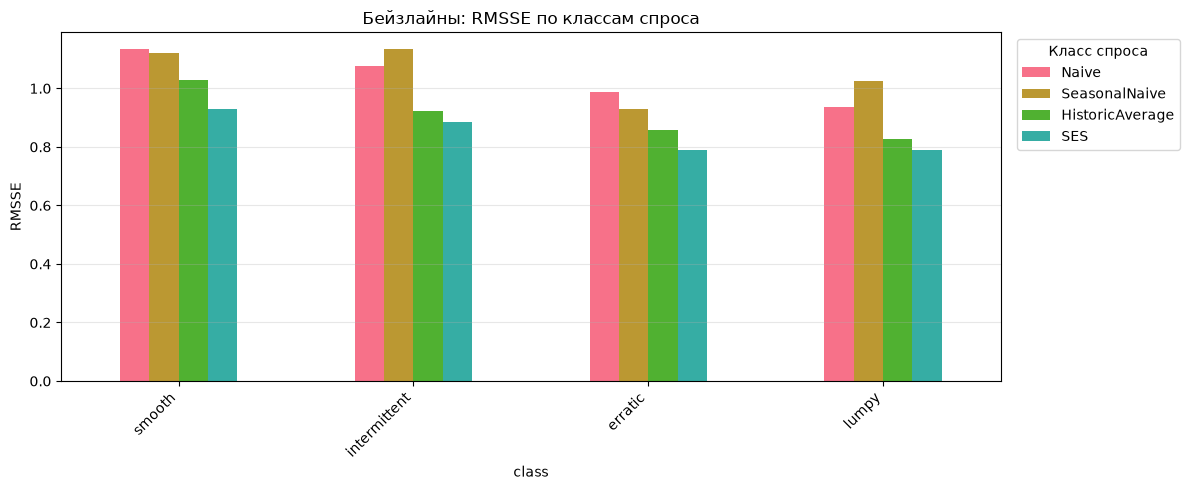

In [21]:
# Визуализация RMSSE по классам
pivot = metric_table(results, 'rmsse').drop(index='all')

pivot.plot(kind='bar', figsize=(12, 5))
plt.ylabel('RMSSE')
plt.title('Бейзлайны: RMSSE по классам спроса')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Класс спроса', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

## Итог

- M5 CA_1: 3049 товаров, ~50% — intermittent/lumpy.
- Классификация ADI/CV² разделяет товары на 4 класса; агрегация меняет класс.
- MAE минимален при нулевом прогнозе для рядов с >50% нулей — метрика не подходит.
- RMSSE, bias — подходящие метрики для прерывистого спроса.
- Бейзлайны: SeasonalNaive(7) часто лучше Naive; SES хуже на прерывистых данных.

**Следующий ноутбук:** специализированные методы — Croston, SBA, TSB, ADIDA, IMAPA.